In [1]:
import pandas as pd
import octopus_slabs
from octopus_slabs.Libs.libPlotting import IndexFunctional
import os
import matplotlib.pyplot as plt
import numpy as np
OctopusData=os.environ["QuantumLaPruns"]
OctopusSources=os.environ["QuantumLaPsources"]
print(OctopusData, OctopusSources)

/home/thibault.derrien/Documents/octopus.data /home/thibault.derrien/Documents/octopus-slabs


# Checking database filtering

In [2]:
# Localhost
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0-TB09/SingleColorSummary"

# BIATRI-SRV results for Martin Kozak
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0"

DatabasePath=OctopusData+"/03-Bulk3D/"
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0"
%cd $DatabasePath

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D


In [124]:
# data=pd.read_csv("SiComplete-2021-10-13-BiatriSrv-v2.2.1-WithToleranceOnField-WithAll.csv", "\t", header=2)
data=pd.read_csv("SiComplete-2022-01-14-BiatriSrv-v2.2.1-WithToleranceOnField-WithAll.csv", "\t", header=2)
datafull=data
data.describe(include="all")
data.dtypes

##JobID                         float64
RunDate                         float64
kgrid                           float64
realmesh                        float64
lambda1                         float64
tau1                            float64
Efield1                         float64
PolarizationAngle               float64
CEP1                            float64
lambda2                         float64
tau2                            float64
Efield2                         float64
CEP2                            float64
delay                           float64
CrossPolar                      float64
TheoryLevel                     float64
InducedFields                   float64
ProbeFieldAmplitude_AU          float64
ProbeFieldDelay_s               float64
Functional                      float64
FrozenHxc                       float64
MoveIon                         float64
NeMax                           float64
NeFinal                         float64
VirtualOscillations             float64


In [125]:
data=datafull
data=data[data.Efield2==0]
data=data[data.kgrid==40]
data

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2482,586197.0,20211221.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.753982,0.0,0.000003,...,0.052258,0.329695,-6.911429e+14,2.473146e+27,1.773881e+41,1.773500e+41,1.0,0.0,1875.0,1153.010893
2483,528466.0,20210929.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.125664,0.0,0.000003,...,0.045713,0.476599,1.057210e+15,2.018731e+27,1.447718e+41,1.447638e+41,1.0,0.0,1250.0,1153.010893
2484,586193.0,20211220.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.502655,0.0,0.000003,...,0.052513,0.433027,-4.935645e+14,2.374915e+27,1.703422e+41,1.703058e+41,1.0,0.0,1750.0,1153.010893
2485,527844.0,20210929.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.062832,0.0,0.000003,...,0.045699,0.477451,1.054200e+15,1.986689e+27,1.424753e+41,1.424660e+41,1.0,0.0,1250.0,1153.010893
2486,528470.0,20210930.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.439823,0.0,0.000003,...,0.050892,0.447269,1.064768e+15,2.309797e+27,1.656421e+41,1.656362e+41,1.0,0.0,1250.0,1153.010893
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2579,516077.0,20210912.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.157080,0.0,0.000003,...,0.000000,0.475732,1.403247e+14,2.038333e+27,1.461907e+41,1.461694e+41,1.0,0.0,1500.0,1153.010893
2580,520136.0,20210919.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.314159,0.0,0.000003,...,0.000000,0.465246,1.936705e+14,2.169291e+27,1.555847e+41,1.555605e+41,1.0,0.0,1500.0,1153.010893
2581,520137.0,20210919.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.471239,0.0,0.000003,...,0.000000,0.441240,2.298413e+14,2.347336e+27,1.683482e+41,1.683282e+41,1.0,0.0,1500.0,1153.010893
2582,586196.0,20211221.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.691150,0.0,0.000003,...,0.052410,0.359824,-4.613766e+14,2.454259e+27,1.760294e+41,1.759957e+41,1.0,0.0,1750.0,1153.010893


In [126]:
datafull=data
data = data[data.lambda1==2656e-9]
data.tau1*1E15
data[np.abs(data.tau1 - 13.945e-15)/data.tau1 < 0.01]

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2482,586197.0,20211221.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.753982,0.0,0.000003,...,0.052258,0.329695,-6.911429e+14,2.473146e+27,1.773881e+41,1.773500e+41,1.0,0.0,1875.0,1153.010893
2483,528466.0,20210929.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.125664,0.0,0.000003,...,0.045713,0.476599,1.057210e+15,2.018731e+27,1.447718e+41,1.447638e+41,1.0,0.0,1250.0,1153.010893
2484,586193.0,20211220.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.502655,0.0,0.000003,...,0.052513,0.433027,-4.935645e+14,2.374915e+27,1.703422e+41,1.703058e+41,1.0,0.0,1750.0,1153.010893
2485,527844.0,20210929.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.062832,0.0,0.000003,...,0.045699,0.477451,1.054200e+15,1.986689e+27,1.424753e+41,1.424660e+41,1.0,0.0,1250.0,1153.010893
2486,528470.0,20210930.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.439823,0.0,0.000003,...,0.050892,0.447269,1.064768e+15,2.309797e+27,1.656421e+41,1.656362e+41,1.0,0.0,1250.0,1153.010893
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2579,516077.0,20210912.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.157080,0.0,0.000003,...,0.000000,0.475732,1.403247e+14,2.038333e+27,1.461907e+41,1.461694e+41,1.0,0.0,1500.0,1153.010893
2580,520136.0,20210919.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.314159,0.0,0.000003,...,0.000000,0.465246,1.936705e+14,2.169291e+27,1.555847e+41,1.555605e+41,1.0,0.0,1500.0,1153.010893
2581,520137.0,20210919.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.471239,0.0,0.000003,...,0.000000,0.441240,2.298413e+14,2.347336e+27,1.683482e+41,1.683282e+41,1.0,0.0,1500.0,1153.010893
2582,586196.0,20211221.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.691150,0.0,0.000003,...,0.052410,0.359824,-4.613766e+14,2.454259e+27,1.760294e+41,1.759957e+41,1.0,0.0,1750.0,1153.010893


# Generating the HHG spectrum as function of CEP

In [16]:
!$QuantumLaPsources/octopus_slabs/Libs/plotHHGspectra.py

  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ====== PULSE 1 =====
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ** Efield1*           size = 2
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ** wavelength1*       size = 1
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ** pulse duration*    size = 1
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ** CEP1               size = 8
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ====== PULSE 2 =====
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ** Efield2*           size = 1
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ** wavelength2*       size = 1
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ** pulse duration*    size = 1
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserP

Size of HHG file: 6000
** Info: interpolating...
** Debug: 59.99999994
** Debug: checking length of new mesh: (600,)
59 deg.
octopus-td.449794*.log
/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-24x24x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field3E9-CEP0.5-theta0.25-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0.5e-15-SinSquared
Size of HHG file: 6000
** Info: interpolating...
** Debug: 90.0
** Debug: checking length of new mesh: (600,)
90 deg.
** Info: Exporting to file HHGspectrumWithCEP-wavelength2656nm-Efield3000000000.csv
** Preparing plot...
  octopus_slabs.Libs.libPlotting - plot2dHeatMap_HHG - INFO - 4800
  octopus_slabs.Libs.libPlotting - plot2dHeatMap_HHG - INFO - 4800
  octopus_slabs.Libs.libPlotting - plot2dHeatMap_HHG - INFO - 4800
  matplotlib.font_manager - _findfont_cached - WARNING - findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans.
  matplotlib.font_

Size of HHG file: 6000
** Info: interpolating...
** Debug: 30.0000006
** Debug: checking length of new mesh: (600,)
30 deg.
octopus-td.449804*.log
/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-24x24x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field1.05E10-CEP0.25-theta0.25-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0.5e-15-SinSquared
Size of HHG file: 6000
** Info: interpolating...
** Debug: 45.0
** Debug: checking length of new mesh: (600,)
45 deg.
octopus-td.449803*.log
/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-24x24x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field1.05E10-CEP0.333333333-theta0.25-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0.5e-15-SinSquared
Size of HHG file: 6000
** Info: interpolating...
** Debug: 59.99999994
** Debug: checking length of new mesh: (600,)
59 deg.
octopus-td.449802*

In [22]:
!ls HHGspectrum*.png

HHGspectrumWithCEP-wavelength2656nm-Efield10500000000.png
HHGspectrumWithCEP-wavelength2656nm-Efield3000000000.png


In [7]:
!display HHGspectrumWithCEP-wavelength2656nm-Efield10500000000.png

display: unable to open X server `localhost:11.0' @ error/display.c/DisplayImageCommand/410.


In [24]:
!display HHGspectrumWithCEP-wavelength2656nm-Efield3000000000.png

^C


# Improving HHG spectra: refining the energy range

In [2]:
from scipy.constants import h, c, e
h*c/e/250E-9

4.959367937328011

Remaining problem is: the energy of the spectrum is far too high. We need to decrease it by a factor of 10. 

For doing so, it is proposed to play with the temporal resolution. Following Heisenberg uncertainty / Noether theorem, we shall simply try to decrease number of samples by 10. Let's see if this brings us more resolution or less. In principle, decreasing time precision should increase energy precision. 

In [472]:
# from scipy.fft import fft, fftfreq, fftshift
from numpy import fft
import numpy as np
from scipy.constants import c, hbar, e
import matplotlib.pyplot as plt

# del t, y
# number of signal points
N = 1_000 #this controls timestep, it does not control time window duration. Then it acts only on the maximum energy one can address in Fourier spectrum

wavelength = 2000e-9; tau=15e-15 #bicolor cycles for excitation rate
#wavelength = 2656e-9; tau=13e-15 #Kozak experimental, pulse rescaled for TDDFT LDA
# wavelength = 3200e-9; tau=30e-15 #Pulse used for orientation-dep excitation rate
# wavelength = 800E-9; tau=30e-15 #Usual configuration of Astrella
omega = 2*np.pi*c/wavelength
T = 2*np.pi/omega
sigma_tau=tau/(2.*np.sqrt(2.*np.log(2.)))

print("One-cycle period: "+str(T)+" seconds")
print("Frequency in Hz:  "+str(omega/1E15)+" PHz")
print("Number of cycles: "+str(tau/T)+" cycles")

t0 = 2*tau #central time
tmin = 0; tmax = 2*t0; #size of the window: controls energy precision. 
# Solution for increasing FFT spectrum precision: increase size of initial signal table, just fill it with zeros.
t = np.linspace(tmin, tmax, N, endpoint=False)
TimeStep=np.diff(t)[0]
print("Timestep: "+str(TimeStep)+" s")
# print(omega*t)
y = np.exp(-0.5*((t-t0)/sigma_tau)**2) * np.sin(omega*t) #+ 0.5*np.sin(80.0 * 2.0*np.pi*t)
# y.resize(30000,)

One-cycle period: 6.671281903963041e-15 seconds
Frequency in Hz:  0.9418257836544266 PHz
Number of cycles: 2.248443435 cycles
Timestep: 6e-17 s


## Import one example of current

In [571]:
# current=np.loadtxt("/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field3E9-CEP0.0-theta0-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/total_current")
# current=np.loadtxt("/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field3E9-CEP0.0-theta0-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/total_current")
current=np.loadtxt("/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-40x40x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field3E9-CEP0.0-theta0.25-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0e-15-SinSquared/td.general/total_current")

In [592]:
from octopus_slabs.Libs.libAtomicUnits import Time_AU_to_SI
t=Time_AU_to_SI(1.)*current[:,0]
y=current[:,2];
TimeStep=np.diff(t)[0]
Elongation=2
t_pad=np.arange(0, (Elongation+1)*(np.max(t)+TimeStep), TimeStep)
y_pad=np.pad(y, (0,Elongation*(len(t))), "mean")
# Let's extend t and y. 


In [593]:
print(np.shape(t_pad), np.shape(y_pad))

(9501,) (9501,)


In [594]:
from octopus_slabs.Libs.libPlotting import SignalDampR
y_damped=SignalDampR(t_pad, y_pad, 2300e-9, 5000)

  octopus_slabs.Libs.libPlotting - SignalDampR - INFO - [libPlotting]** Info: HHG dampingTime: 8 fs.
  octopus_slabs.Libs.libPlotting - SignalDampR - INFO - [libPlotting]** Info: HHG final instant: 5000000000000000000 fs.
  octopus_slabs.Libs.libPlotting - SignalDampR - INFO - [libPlotting]** Info: omega = 818978942308197


## Plotting of defined pulse

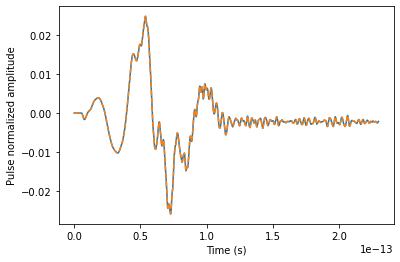

In [595]:
plt.figure()
plt.plot(t,y, "-")
# plt.plot(t_pad,y_pad, "-")
plt.plot(t_pad,y_damped, "--")
# plt.xlim([0,tmax])
plt.xlabel("Time (s)")
plt.ylabel("Pulse normalized amplitude")
plt.show()

## Definition of Fourier part

### Using numpy FFT (double precision)

In [596]:
yf = fft.rfft(y_damped)
xf = 2.*np.pi*fft.rfftfreq(len(t_pad), d=TimeStep)
# xf = fft.fftshift(xf) #no effect in real space
photon_energy = hbar*xf/e #converting in eV

yplot = yf
# yplot = fft.fftshift(yf) #no effect in real space

print(np.shape(photon_energy))
print(np.shape(yplot))

(4751,)
(4751,)


In [597]:
np.shape(yf)
print(type(yf[0]))
np.empty(np.shape(yf), dtype=type(yf[0]))

<class 'numpy.complex128'>


array([ 6.91572043e-310+6.91572043e-310j,
        4.68309365e-310+4.68309365e-310j,
       -7.24838177e-001-9.48177749e+000j, ...,
        1.08122835e-003-8.30751107e-007j,
        1.08125166e-003-6.49368346e-007j,
        1.08123400e-003-9.23177628e-008j])

In [598]:
import copy

In [599]:
# copy.copy?

In [600]:
import pyfftw
yf2=np.zeros(np.shape(yf),dtype=type(yf[0]))
instance=pyfftw.FFTW(y_damped,yf2) #input, output

In [601]:
pyfftw.FFTW.execute(instance)

In [602]:
max(np.abs(yf2-yplot))

24.371812103165453

### Plotting

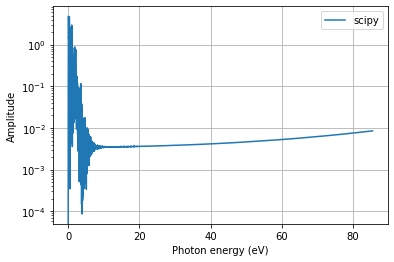

In [603]:
plt.figure()
# plt.semilogy(xf, 1.0/N * np.abs(yplot)) #amplitude
plt.semilogy(photon_energy, photon_energy**2 * np.abs(yplot)**2, "-", label="scipy") #Larmor formula
# plt.semilogy(photon_energy, photon_energy**2 * np.abs(yf2)**2,"--", label="fftw") #Larmor formula
# plt.xlabel("Frequency (Hz)")
plt.legend(loc="best")
plt.xlabel("Photon energy (eV)")
plt.ylabel("Amplitude")
# plt.xlim(0,10)
plt.grid()
plt.show()

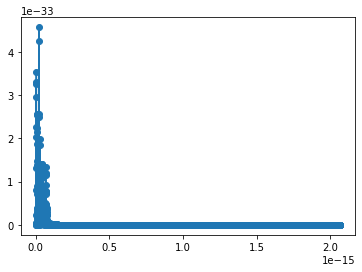

In [448]:
plt.figure()
# plt.xticks(int(photon_energy))
# plt.xlim(0,5)
plt.plot(photon_energy, photon_energy**2 * np.abs(yplot)**2, "o-")
plt.show()

## SinSquared & SinFourth harmonic spectra

In [130]:
# from octopus_slabs.Pulses.GeneratePulse import GeneratePulse
from spp_extended_theory.Keldysh.libKeldyshPulses import PulseSquaredSinTemporalShape
from scipy.constants import pi

print("Laser wavelength: ", wavelength, "m\n","Pulse duration: ", tau, "s")
RiseCycle=2
PulseDelay=0e0
power=8

omega = 2.*pi*c/wavelength
print("Photon energy: ", hbar*omega/e, "eV")
tauRise = 2.*pi*RiseCycle / (omega)
print("Rise cycle duration: ", tauRise, "seconds")
ComputingT = 1*(tauRise+tau+tauRise+PulseDelay)
print("Computing physical time range: ", ComputingT, "seconds")
PeakField = 1E9


tmin = 0e-15
tmax = float(ComputingT)
Number = 100_000 #NOTE: better to put too many nodes here ! Better to have something wider than planned octopus time steps. 
timestep=(tmax-tmin)/(Number+1.)
t = np.arange(tmin, tmax, timestep)
tauSafe = wavelength / c #1 optical cycle to ensure having dA/dt = 0 at instant zero !
# Envelope, Field = PulseSmoothTopHatShape(t, tau, tauRise, PeakField, wavelength, CEP, t0+tauSafe, PulseDelay, power)
Envelope, Field = PulseSquaredSinTemporalShape(t, tau, PeakField, wavelength, CEP=0., t0=tau+tauSafe, PulseDelay=0., power=power)
# Envelope     = GeneratePulse(t, tau, tauRise, PeakField, wavelength, 2.*pi*CEP, tau/2.+tauRise+tauSafe, PulseDelay+0.1E-15, power)
# print(Field)

Laser wavelength:  2e-06 m
 Pulse duration:  1.5e-14 s
Photon energy:  0.6199209921660014 eV
Rise cycle duration:  1.3342563807926082e-14 seconds
Computing physical time range:  4.1685127615852163e-14 seconds


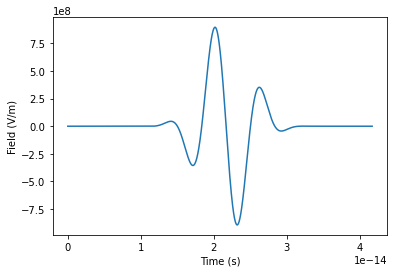

In [131]:
y=np.real(Field)
plt.figure()
plt.plot(t,y)
# plt.plot(Envelope[0]*timestep,Envelope[1])
plt.xlabel("Time (s)")
plt.ylabel("Field (V/m)")
# plt.xlim([0,6*tau])
plt.show()

In [132]:
yf = fft.rfft(y)
xf = 2.*np.pi*fft.rfftfreq(len(t), d=timestep)
# xf = fft.fftshift(xf) #no effect in real space
photon_energy = hbar*xf/e #converting in eV

yplot = yf
# yplot = fft.fftshift(yf) #no effect in real space

print(np.shape(photon_energy))
print(np.shape(yplot))

(50001,)
(50001,)


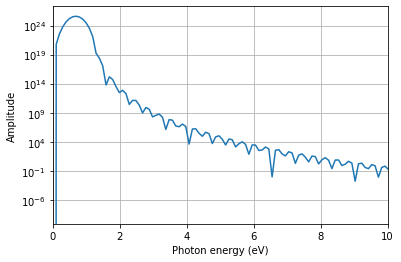

In [133]:
plt.figure()
# plt.semilogy(xf, 1.0/N * np.abs(yplot)) #amplitude
plt.semilogy(photon_energy, photon_energy**2 * np.abs(yplot)**2) #Larmor formula
# plt.xlabel("Frequency (Hz)")
plt.xlabel("Photon energy (eV)")
plt.ylabel("Amplitude")
plt.xlim(0,10)
plt.grid()
plt.show()

In [272]:
hbar*2*pi*c/2E-6/e #photon energy in eV

0.6199209921660013

## Optimization of the Fourier transform

In [134]:
print(np.shape(y))
print(np.shape(t))

(100001,)
(100001,)


In [135]:
t2 = np.arange(tmin, 2*tmax, TimeStep)
y.resize(20_000,refcheck=False)

plt.figure()
plt.plot(t2,y)
plt.xlim([0,1.5e-13])
plt.show()

ValueError: resize only works on single-segment arrays

# Harmonic spectrum as function of angle of polarization
## Fetching runs computed with various angles of polarization

In [13]:
data=datafull
datatmp=data

## 1. Searching for runs that were prepared for various angles of polarization...
datatmp=datatmp[datatmp.PolarizationAngle!=0]
## 2. Filtering the non-zero CEP1
datatmp=datatmp[datatmp.CEP1==0]
## 3. Checking variety of wavelengtha and pulse durations
print("Wavelengths: ", set(datatmp.lambda1))
print("Pulse duration: ", set(datatmp.tau1))

Wavelengths:  {2.656e-06}
Pulse duration:  {1.3944999999999999e-14}


In [16]:
## 4. Since data are fully matching with case of M. Kozak, lets isolate by wavelength directly, keeping all orientation angles
datatmp=datafull
datatmp=datatmp[datatmp.CEP1==0]
datatmp=datatmp[datatmp.Efield1==3E9]
datatmp=datatmp[datatmp.lambda1==2656e-9]
datatmp=datatmp[np.abs(datatmp.tau1 - 13.945e-15)/datatmp.tau1 < 0.01]
print("Fields: ", set(datatmp.Efield1))

Fields:  {3000000000.0}


In [17]:
datatmp

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2482,528466.0,20210929.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.125664,0.0,0.000003,...,0.045713,0.476599,1.057210e+15,2.018731e+27,1.447718e+41,1.447638e+41,1.0,0.0,1250.0,1153.010893
2483,528471.0,20210930.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.502655,0.0,0.000003,...,0.052513,0.433027,1.054637e+15,2.374915e+27,1.703104e+41,1.703058e+41,1.0,0.0,1250.0,1153.010893
2484,527844.0,20210929.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.062832,0.0,0.000003,...,0.045699,0.477451,1.054200e+15,1.986689e+27,1.424753e+41,1.424660e+41,1.0,0.0,1250.0,1153.010893
2485,528470.0,20210930.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.439823,0.0,0.000003,...,0.050892,0.447269,1.064768e+15,2.309797e+27,1.656421e+41,1.656362e+41,1.0,0.0,1250.0,1153.010893
2491,498934.0,20210803.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.000000,0.0,0.000003,...,0.000000,0.477130,7.007967e+14,1.974000e+27,1.415733e+41,1.415561e+41,1.0,0.0,1375.0,1153.010893
2496,528468.0,20210930.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.251327,0.0,0.000003,...,0.047047,0.471900,1.065911e+15,2.113984e+27,1.516003e+41,1.515944e+41,1.0,0.0,1250.0,1153.010893
2497,526584.0,20210930.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.376991,0.0,0.000003,...,0.049758,0.456884,1.068931e+15,2.233046e+27,1.601389e+41,1.601324e+41,1.0,0.0,1250.0,1153.010893
2498,516077.0,20210912.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.157080,0.0,0.000003,...,0.000000,0.475732,1.403247e+14,2.038333e+27,1.461907e+41,1.461694e+41,1.0,0.0,1500.0,1153.010893
2499,520136.0,20210919.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.314159,0.0,0.000003,...,0.000000,0.465246,1.936705e+14,2.169291e+27,1.555847e+41,1.555605e+41,1.0,0.0,1500.0,1153.010893
2500,520137.0,20210919.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.471239,0.0,0.000003,...,0.000000,0.441240,2.298413e+14,2.347336e+27,1.683482e+41,1.683282e+41,1.0,0.0,1500.0,1153.010893


We need more computations!! 

1. HHG spectrum convergence test: k=32, k=40
2. Run multiple orientations with converged k-grid. Where are multiple orientations I computed before? 
3. Run multiple CEP again with converged k-grid
4. Run real pulse shape with converged k-grid

# Experimental pulse reconstruction (~15 fs)

Martin Kozak provided cycle-resolved field. Let's see what can be prepared from this. 

In [24]:
filepath=OctopusSources+"/03-Bulk3D/"
%cd $filepath

/home/thibault.derrien/Documents/octopus-slabs/03-Bulk3D


In [111]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c, pi
field_exp=np.loadtxt("Kozak_field.dat") #high precision data
# field_exp=np.loadtxt("Kozak_field_2.dat", delimiter=",") #low precision data
t=field_exp[:,0]
Er=field_exp[:,1]
Ei=field_exp[:,2]
Eexpc=Er+1j*Ei


Formula as described by Martin: 
$E_{\mathrm{exp}}(t)=\tilde{E} \times e^{i \omega t}$ where $\tilde{E}$ is given in file. 

In [112]:
wavelength=2020e-9
omega=2*np.pi*c/wavelength
Eexp=Eexpc*np.exp(1j*omega*t)
y=np.real(Eexp)

In [113]:
print(np.shape(t), np.shape(Eexp))

(2551,) (2551,)


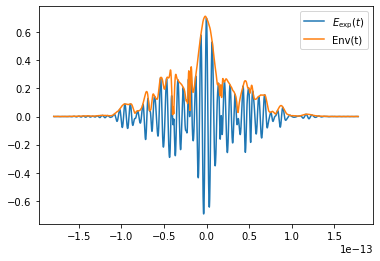

In [114]:
plt.figure()
plt.plot(t, np.real(Eexp), label=r'$E_{\mathrm{exp}}(t)$')
plt.plot(t, np.sqrt(np.real(Eexp*np.conj(Eexp))), label=r'Env(t)')
# plt.xlim([-0.5e-13,0.5e-13])
plt.legend()

In [115]:
yf = fft.rfft(y)
xf = 2.*np.pi*fft.rfftfreq(len(t), d=TimeStep)
# xf = fft.fftshift(xf) #no effect in real space
photon_energy = hbar*xf/e #converting in eV

yplot = yf
# yplot = fft.fftshift(yf) #no effect in real space

print(np.shape(photon_energy))
print(np.shape(yplot))

(1276,)
(1276,)


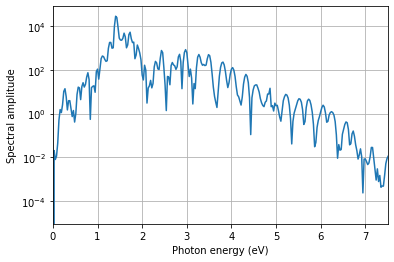

In [121]:
plt.figure()
# plt.semilogy(xf, 1.0/N * np.abs(yplot)) #amplitude
plt.semilogy(photon_energy, photon_energy**2 * np.abs(yplot)**2) #Larmor formula
# plt.xlabel("Frequency (Hz)")
plt.xlabel("Photon energy (eV)")
plt.ylabel("Spectral amplitude")
plt.xlim(0,7.5)
plt.grid()
plt.show()

# Preparing pulses for conserving number of cycles

In [89]:
# from scipy.fft import fft, fftfreq, fftshift
from numpy import fft
import numpy as np
from scipy.constants import c, hbar, e
import matplotlib.pyplot as plt

# del t, y
# number of signal points
N = 10_000 #this controls timestep, it does not control time window duration. Then it acts only on the maximum energy one can address in Fourier spectrum

# wavelength = 1.3679687500000002e-06; tau=4.5630525835309716e-15 #1 cycle of 1030 nm renormalized with LDA->EXP band gap
wavelength=2000e-9; tau=15e-15 #Kozak experimental for angle dependence, pulse rescaled for TDDFT LDA
# wavelength = 2656e-9; tau=13e-15 #Kozak experimental, pulse rescaled for TDDFT LDA
#wavelength = 3200e-9; tau=30e-15 #Pulse used for orientation-dep excitation rate
CEP=0e0 #1*pi

omega = 2*np.pi*c/wavelength
T = 2*np.pi/omega

print("One-cycle period: "+str(T)+" seconds")
print("Frequency in Hz:  "+str(omega/1E15)+" PHz")
print("Number of cycles: "+str(tau/T)+" cycles")

One-cycle period: 6.671281903963041e-15 seconds
Frequency in Hz:  0.9418257836544266 PHz
Number of cycles: 3.747405725 cycles


## Normalization of wavelength to bandgap

Each pulse should be renormalized to the functional band gap energy

$\frac {\hbar \omega_{th}} {E_g^{LDA}} = \frac{\hbar \omega_{exp}}{ E_g^{exp} }$

In [87]:
wavelength_exp = 2000e-9 #or 2300e-9 ? 
Eg_exp = 3.4*e #direct band gap at 300 K
Eg_th  = 2.56*e

wavelength_th = Eg_exp/Eg_th * wavelength_exp

print(wavelength_th)

2.6562499999999998e-06


## Deducing pulse duration from normalized wavelength

In [88]:
from scipy.constants import pi, c

number_cycles = 3.747405725 #cycles

omega_exp = 2*pi*c/wavelength_exp
omega_th = 2*pi*c/wavelength_th

T_exp = 2*np.pi/omega_exp
T_th  = 2*np.pi/omega_th

tau_th = number_cycles * T_th
print("Renormalized pulse duration: ", tau_th)

Renormalized pulse duration:  3.3203125e-14
